# Classification of Income Level — Adult Census Dataset
**Assignment:** Five classification models (Logistic Regression, Decision Tree, KNN, Naive Bayes, Random Forest) compared on this dataset.

**Name:** Kinjal Kanjilal |  **Roll no.:** 2026ct05111

**Contents**
1. Dataset selection and exploration
2. Data preprocessing
3. Model implementation and evaluation
4. Comparison and observations

In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix, roc_curve)

RANDOM_STATE = 42          # fixed seed used everywhere
np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")

## Step 1: Dataset Choice

### Dataset: Adult (Census Income) — UCI Machine Learning Repository
Source: https://archive.ics.uci.edu/dataset/2/adult (also available on Kaggle as "Adult Census Income").

### Why this dataset?
- **Meets all requirements:** 14 features (min. 12) and 48,842 instances (min. 1,000).
- **Real missing values:** `workclass`, `occupation` and `native-country` contain missing entries (coded as `?`), so imputation is genuinely required.
- **Class imbalance:** about 76% of people earn `<=50K` and 24% earn `>50K`, so imbalance has to be examined and accuracy alone is misleading.
- **Mixed feature types:** numeric and categorical features make encoding and scaling meaningful.
- **Well-known benchmark** with a clear real-world task (predicting income level from demographic data).

### Target variable
`income`: binary, `<=50K` (class 0) vs `>50K` (class 1).

In [4]:
df = pd.read_csv("test_data.csv")
print("Loaded from test_data.csv")

print("Shape:", df.shape)
df.head()

Loaded from test_data.csv
Shape: (9758, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,40,Private,126868,HS-grad,9,Divorced,Machine-op-inspct,Not-in-family,Black,Male,0,0,40,United-States,<=50K
1,84,Private,188328,HS-grad,9,Widowed,Prof-specialty,Not-in-family,White,Female,0,0,16,United-States,<=50K
2,71,NaN,128529,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,0,20,United-States,<=50K
3,25,Private,71351,1st-4th,2,Never-married,Other-service,Other-relative,White,Male,0,0,25,El-Salvador,<=50K
4,39,Private,204501,Masters,14,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,50,United-States,>50K


### 1.1 Dataset overview and feature types

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9758 entries, 0 to 9757
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             9758 non-null   int64 
 1   workclass       9181 non-null   object
 2   fnlwgt          9758 non-null   int64 
 3   education       9758 non-null   object
 4   education-num   9758 non-null   int64 
 5   marital-status  9758 non-null   object
 6   occupation      9179 non-null   object
 7   relationship    9758 non-null   object
 8   race            9758 non-null   object
 9   sex             9758 non-null   object
 10  capital-gain    9758 non-null   int64 
 11  capital-loss    9758 non-null   int64 
 12  hours-per-week  9758 non-null   int64 
 13  native-country  9573 non-null   object
 14  income          9758 non-null   object
dtypes: int64(6), object(9)
memory usage: 1.1+ MB


In [6]:
target = "income"
num_features = df.drop(columns=target).select_dtypes(include="number").columns.tolist()
cat_features = df.drop(columns=target).select_dtypes(exclude="number").columns.tolist()

print(f"Instances : {df.shape[0]}")
print(f"Features  : {df.shape[1] - 1}")
print(f"Target    : {target}\n")
print(f"Numerical features   ({len(num_features)}): {num_features}")
print(f"Categorical features ({len(cat_features)}): {cat_features}")

Instances : 9758
Features  : 14
Target    : income

Numerical features   (6): ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical features (8): ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,9758.0,38.865341,13.767179,17.0,28.0,37.0,48.0,90.0
fnlwgt,9758.0,189015.824657,105262.895634,18827.0,117263.0,178058.0,235979.0,1455435.0
education-num,9758.0,10.080242,2.579159,1.0,9.0,10.0,13.0,16.0
capital-gain,9758.0,1127.510248,7639.078285,0.0,0.0,0.0,0.0,99999.0
capital-loss,9758.0,89.540787,407.071643,0.0,0.0,0.0,0.0,4356.0
hours-per-week,9758.0,40.167965,12.316051,1.0,40.0,40.0,45.0,99.0


### 1.2 Class distribution (imbalance check)

        count  percentage
income                   
<=50K    7422       76.06
>50K     2336       23.94

Imbalance ratio (majority : minority) = 3.18 : 1


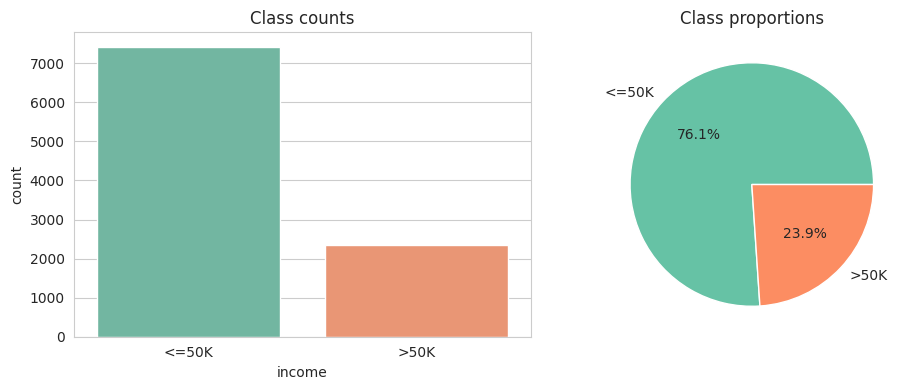

In [8]:
counts = df[target].value_counts()
percent = df[target].value_counts(normalize=True) * 100
print(pd.DataFrame({"count": counts, "percentage": percent.round(2)}))
print(f"\nImbalance ratio (majority : minority) = {counts.max() / counts.min():.2f} : 1")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x=target, data=df, ax=ax[0], palette="Set2")
ax[0].set_title("Class counts")
ax[1].pie(counts, labels=counts.index, autopct="%.1f%%", colors=sns.color_palette("Set2"))
ax[1].set_title("Class proportions")
plt.tight_layout(); plt.show()

**Observation:** The dataset is moderately imbalanced (about 3:1). A model that always predicts `<=50K` would reach ~76% accuracy, so Precision, Recall, F1, AUC and MCC are important in addition to Accuracy. We use a **stratified** split to keep this ratio in both train and test sets.

## Step 2: Data Preprocessing

### 2.1 Identify missing values

In [9]:
missing = df.isnull().sum()
missing_df = pd.DataFrame({"missing": missing, "percent": (missing / len(df) * 100).round(2)})
missing_df[missing_df["missing"] > 0]

,missing,percent
workclass,577,5.91
occupation,579,5.93
native-country,185,1.90


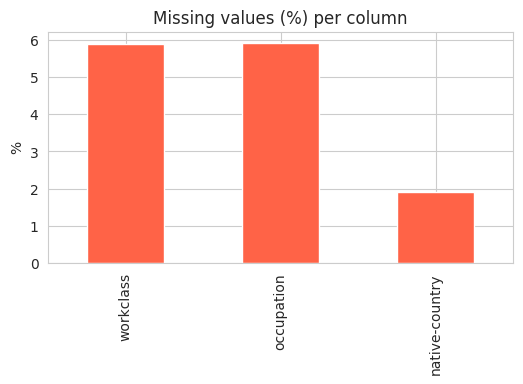

In [10]:
missing_df[missing_df["missing"] > 0]["percent"].plot(kind="bar", color="tomato", figsize=(6, 3))
plt.title("Missing values (%) per column"); plt.ylabel("%"); plt.show()

**Handling strategy:** `workclass`, `occupation` and `native-country` have missing values (all categorical). They are imputed with the **most frequent value (mode)**, and any numeric column would be imputed with the **median**. The imputers are placed inside a `ColumnTransformer` and **fitted only on the training data** (see 2.5) to avoid data leakage.

### 2.2 Identify and handle duplicates

In [11]:
n_dup = df.duplicated().sum()
print("Duplicate rows:", n_dup)
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 0
Shape after removing duplicates: (9758, 15)


Exact duplicate rows are removed *before* splitting, so the same record cannot appear in both train and test sets.

### 2.3 Separate features and target, encode the target

In [12]:
X = df.drop(columns=target)
le = LabelEncoder()
y = pd.Series(le.fit_transform(df[target]), name=target)
print("Target mapping:", dict(zip(le.classes_, le.transform(le.classes_))))

Target mapping: {'<=50K': np.int64(0), '>50K': np.int64(1)}


### 2.4 Train-test split (80:20, stratified, fixed seed)
The split happens **before** any imputation, encoding or scaling.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Test:", X_test.shape)

dist = pd.DataFrame({
    "Full data": y.value_counts(normalize=True),
    "Train": y_train.value_counts(normalize=True),
    "Test": y_test.value_counts(normalize=True)
}).round(4) * 100
print("\nClass distribution (%):"); dist

Train: (7806, 14)  Test: (1952, 14)

Class distribution (%):


,Full data,Train,Test
income,,,
0,76.06,76.06,76.08
1,23.94,23.94,23.92


### 2.5 Imputation, encoding and scaling (fit on training data only)
- **Numeric features:** median imputation, then `StandardScaler` (needed for Logistic Regression and KNN, which are distance/gradient based).
- **Categorical features:** mode imputation, then `OneHotEncoder` (`handle_unknown="ignore"` so unseen test categories do not break the pipeline). One-hot encoding is used because the categories are nominal with no natural order.
- `fit_transform` is called on the training set; only `transform` is called on the test set.

In [14]:
num_features = X_train.select_dtypes(include="number").columns.tolist()
cat_features = X_train.select_dtypes(exclude="number").columns.tolist()

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, num_features),
    ("cat", categorical_pipe, cat_features)
])

X_train_p = preprocessor.fit_transform(X_train)   # fit ONLY on training data
X_test_p  = preprocessor.transform(X_test)        # test data is only transformed

feature_names = preprocessor.get_feature_names_out()
print("Processed train shape:", X_train_p.shape)
print("Processed test shape :", X_test_p.shape)
print("Missing values left (train/test):", np.isnan(X_train_p).sum(), np.isnan(X_test_p).sum())

Processed train shape: (7806, 103)
Processed test shape : (1952, 103)
Missing values left (train/test): 0 0


In [15]:
pd.DataFrame(X_train_p, columns=feature_names).head()

,num__age,num__fnlwgt,num__education-num,num__capital-gain,num__capital-loss,num__hours-per-week,cat__workclass_Federal-gov,cat__workclass_Local-gov,cat__workclass_Private,cat__workclass_Self-emp-inc,...,cat__native-country_Portugal,cat__native-country_Puerto-Rico,cat__native-country_Scotland,cat__native-country_South,cat__native-country_Taiwan,cat__native-country_Thailand,cat__native-country_Trinadad&Tobago,cat__native-country_United-States,cat__native-country_Vietnam,cat__native-country_Yugoslavia
0,-1.446965,0.489467,-0.028401,-0.149787,-0.218167,-0.021023,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,-0.937332,-0.014203,-0.415309,-0.149787,-0.218167,-0.021023,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,-1.228551,0.404163,-0.415309,-0.149787,-0.218167,-1.645847,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,-0.500503,-0.071473,-0.415309,-0.149787,-0.218167,0.385183,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,-1.301356,-0.252366,-0.028401,-0.149787,-0.218167,0.385183,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


## Step 3: Classification Models and Evaluation

All five models are trained on the **same** preprocessed training set and evaluated on the **same** test set.
Metrics are computed for the positive class (`>50K`). AUC uses predicted probabilities.

In [16]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree":       DecisionTreeClassifier(random_state=RANDOM_STATE),
    "KNN":                 KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes (Gaussian)": GaussianNB(),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
}

results, fitted, probas, preds = [], {}, {}, {}

for name, model in models.items():
    model.fit(X_train_p, y_train)
    y_pred = model.predict(X_test_p)
    y_prob = model.predict_proba(X_test_p)[:, 1]

    fitted[name], preds[name], probas[name] = model, y_pred, y_prob
    results.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "AUC":       roc_auc_score(y_test, y_prob),
        "Precision": precision_score(y_test, y_pred),
        "Recall":    recall_score(y_test, y_pred),
        "F1 Score":  f1_score(y_test, y_pred),
        "MCC":       matthews_corrcoef(y_test, y_pred),
    })

results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df

,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Model,,,,,,
Logistic Regression,0.8484,0.9017,0.7464,0.5546,0.6364,0.5527
Decision Tree,0.8079,0.7402,0.5962,0.6103,0.6032,0.4765
KNN,0.8432,0.8669,0.6921,0.6210,0.6546,0.5550
Naive Bayes (Gaussian),0.4139,0.6810,0.2840,0.9529,0.4376,0.2116
Random Forest,0.8560,0.8987,0.7397,0.6146,0.6713,0.5843


### 3.1 Confusion matrices

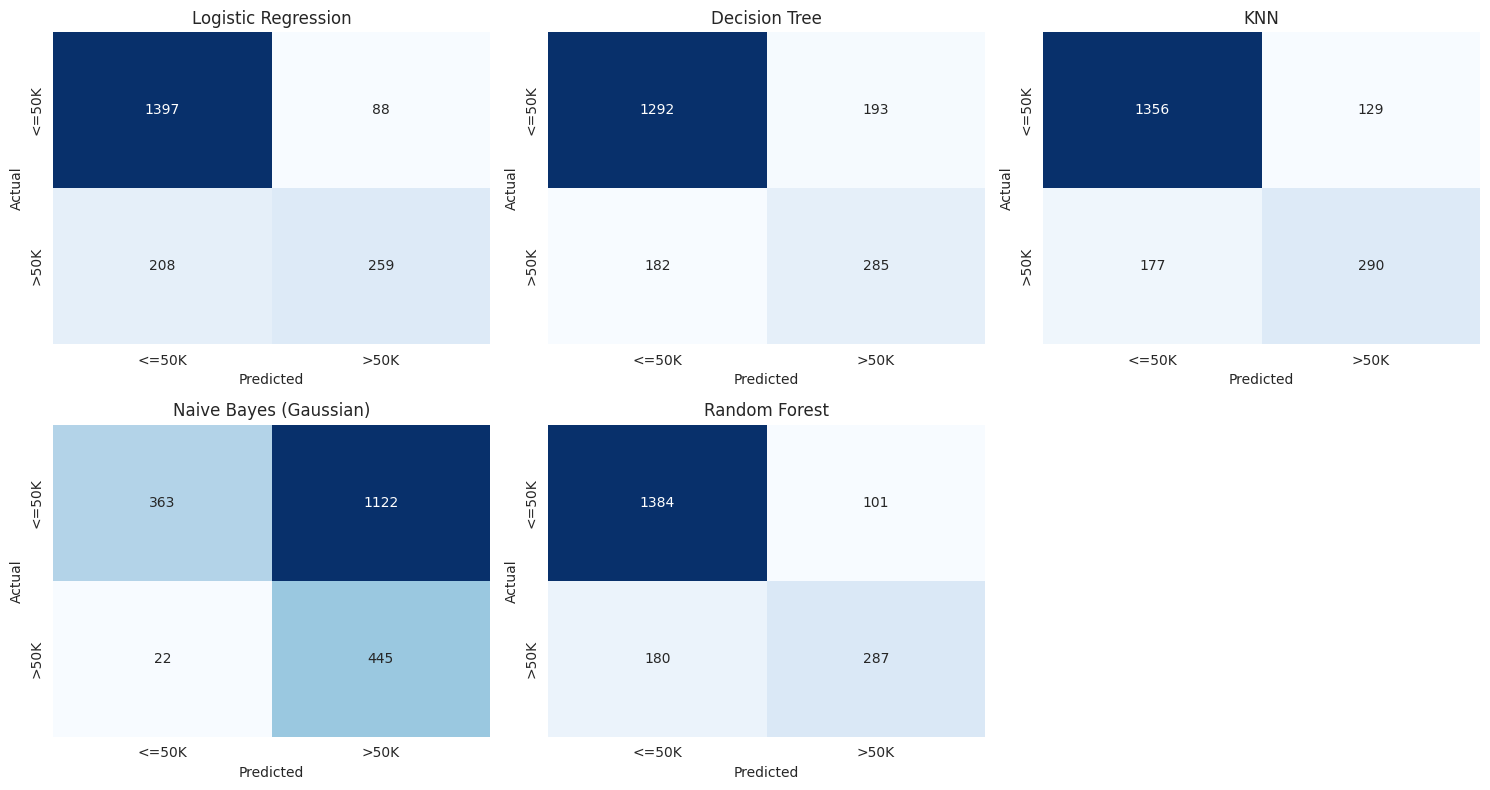

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()
for ax, (name, y_pred) in zip(axes, preds.items()):
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=le.classes_, yticklabels=le.classes_, ax=ax)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
axes[-1].axis("off")
plt.tight_layout(); plt.show()

### 3.2 ROC curves

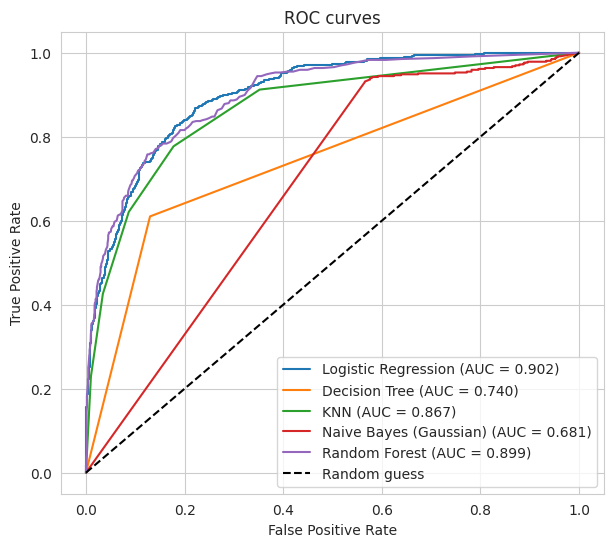

In [18]:
plt.figure(figsize=(7, 6))
for name, y_prob in probas.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, y_prob):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC curves"); plt.legend(loc="lower right"); plt.show()

## Step 4: Model Comparison

In [19]:
results_df.style.background_gradient(cmap="YlGn", axis=0).format("{:.4f}")

,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Model,,,,,,
Logistic Regression,0.8484,0.9017,0.7464,0.5546,0.6364,0.5527
Decision Tree,0.8079,0.7402,0.5962,0.6103,0.6032,0.4765
KNN,0.8432,0.8669,0.6921,0.6210,0.6546,0.5550
Naive Bayes (Gaussian),0.4139,0.6810,0.2840,0.9529,0.4376,0.2116
Random Forest,0.8560,0.8987,0.7397,0.6146,0.6713,0.5843


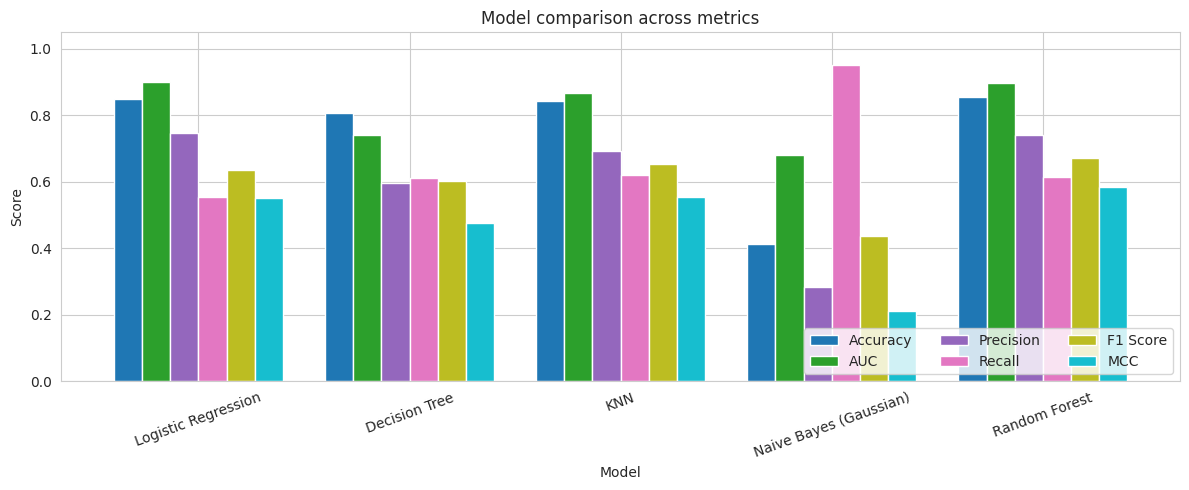

In [20]:
results_df.plot(kind="bar", figsize=(12, 5), colormap="tab10", width=0.8)
plt.title("Model comparison across metrics"); plt.ylabel("Score"); plt.ylim(0, 1.05)
plt.xticks(rotation=20); plt.legend(loc="lower right", ncol=3); plt.tight_layout(); plt.show()

In [21]:
print("Best model per metric:")
print(results_df.idxmax())

Best model per metric:
Accuracy              Random Forest
AUC             Logistic Regression
Precision       Logistic Regression
Recall       Naive Bayes (Gaussian)
F1 Score              Random Forest
MCC                   Random Forest
dtype: object


In [22]:
import os
import joblib

os.makedirs("model", exist_ok=True)

for name, model in fitted.items():
    filename = name.lower().replace(" ", "_").replace("(", "").replace(")", "")
    joblib.dump(model, f"model/{filename}.pkl", compress=3)
    print(f"Saved: model/{filename}.pkl")

Saved: model/logistic_regression.pkl
Saved: model/decision_tree.pkl
Saved: model/knn.pkl
Saved: model/naive_bayes_gaussian.pkl
Saved: model/random_forest.pkl
